## TP3 

# Trabajos Prácticos 3: Detección de Logotipo por Template Matching

**Objetivos:**
1. Obtener una única detección del logotipo por imagen sin falsos positivos.
2. Detectar múltiples instancias del logotipo en `coca_multi.png`.
3. Generalizar el algoritmo para todas las imágenes del dataset visualizando Bounding Boxes y nivel de confianza.

#### 1. Obtener una única detección del logotipo por imagen sin falsos positivos.

pattern.png:orig -> 233 puntos clave
pattern.png:negro_s_blanco -> 414 puntos clave
pattern.png:blanco_s_rojo -> 413 puntos clave
pattern.png:blanco_s_oscuro -> 411 puntos clave

RESULTADOS
----------------------------------------------------------------------
COCA-COLA-LOGO.jpg         DETECTADO  inliers=26   variante=pattern.png:blanco_s_rojo
coca_logo_1.png            DETECTADO  inliers=62   variante=pattern.png:blanco_s_rojo
coca_logo_2.png            DETECTADO  inliers=37   variante=pattern.png:blanco_s_rojo
coca_multi.png             sin detección (máx inliers válidos: 0)
coca_retro_1.png           DETECTADO  inliers=11   variante=pattern.png:orig
coca_retro_2.png           DETECTADO  inliers=30   variante=pattern.png:blanco_s_rojo
logo_1.png                 DETECTADO  inliers=33   variante=pattern.png:blanco_s_rojo


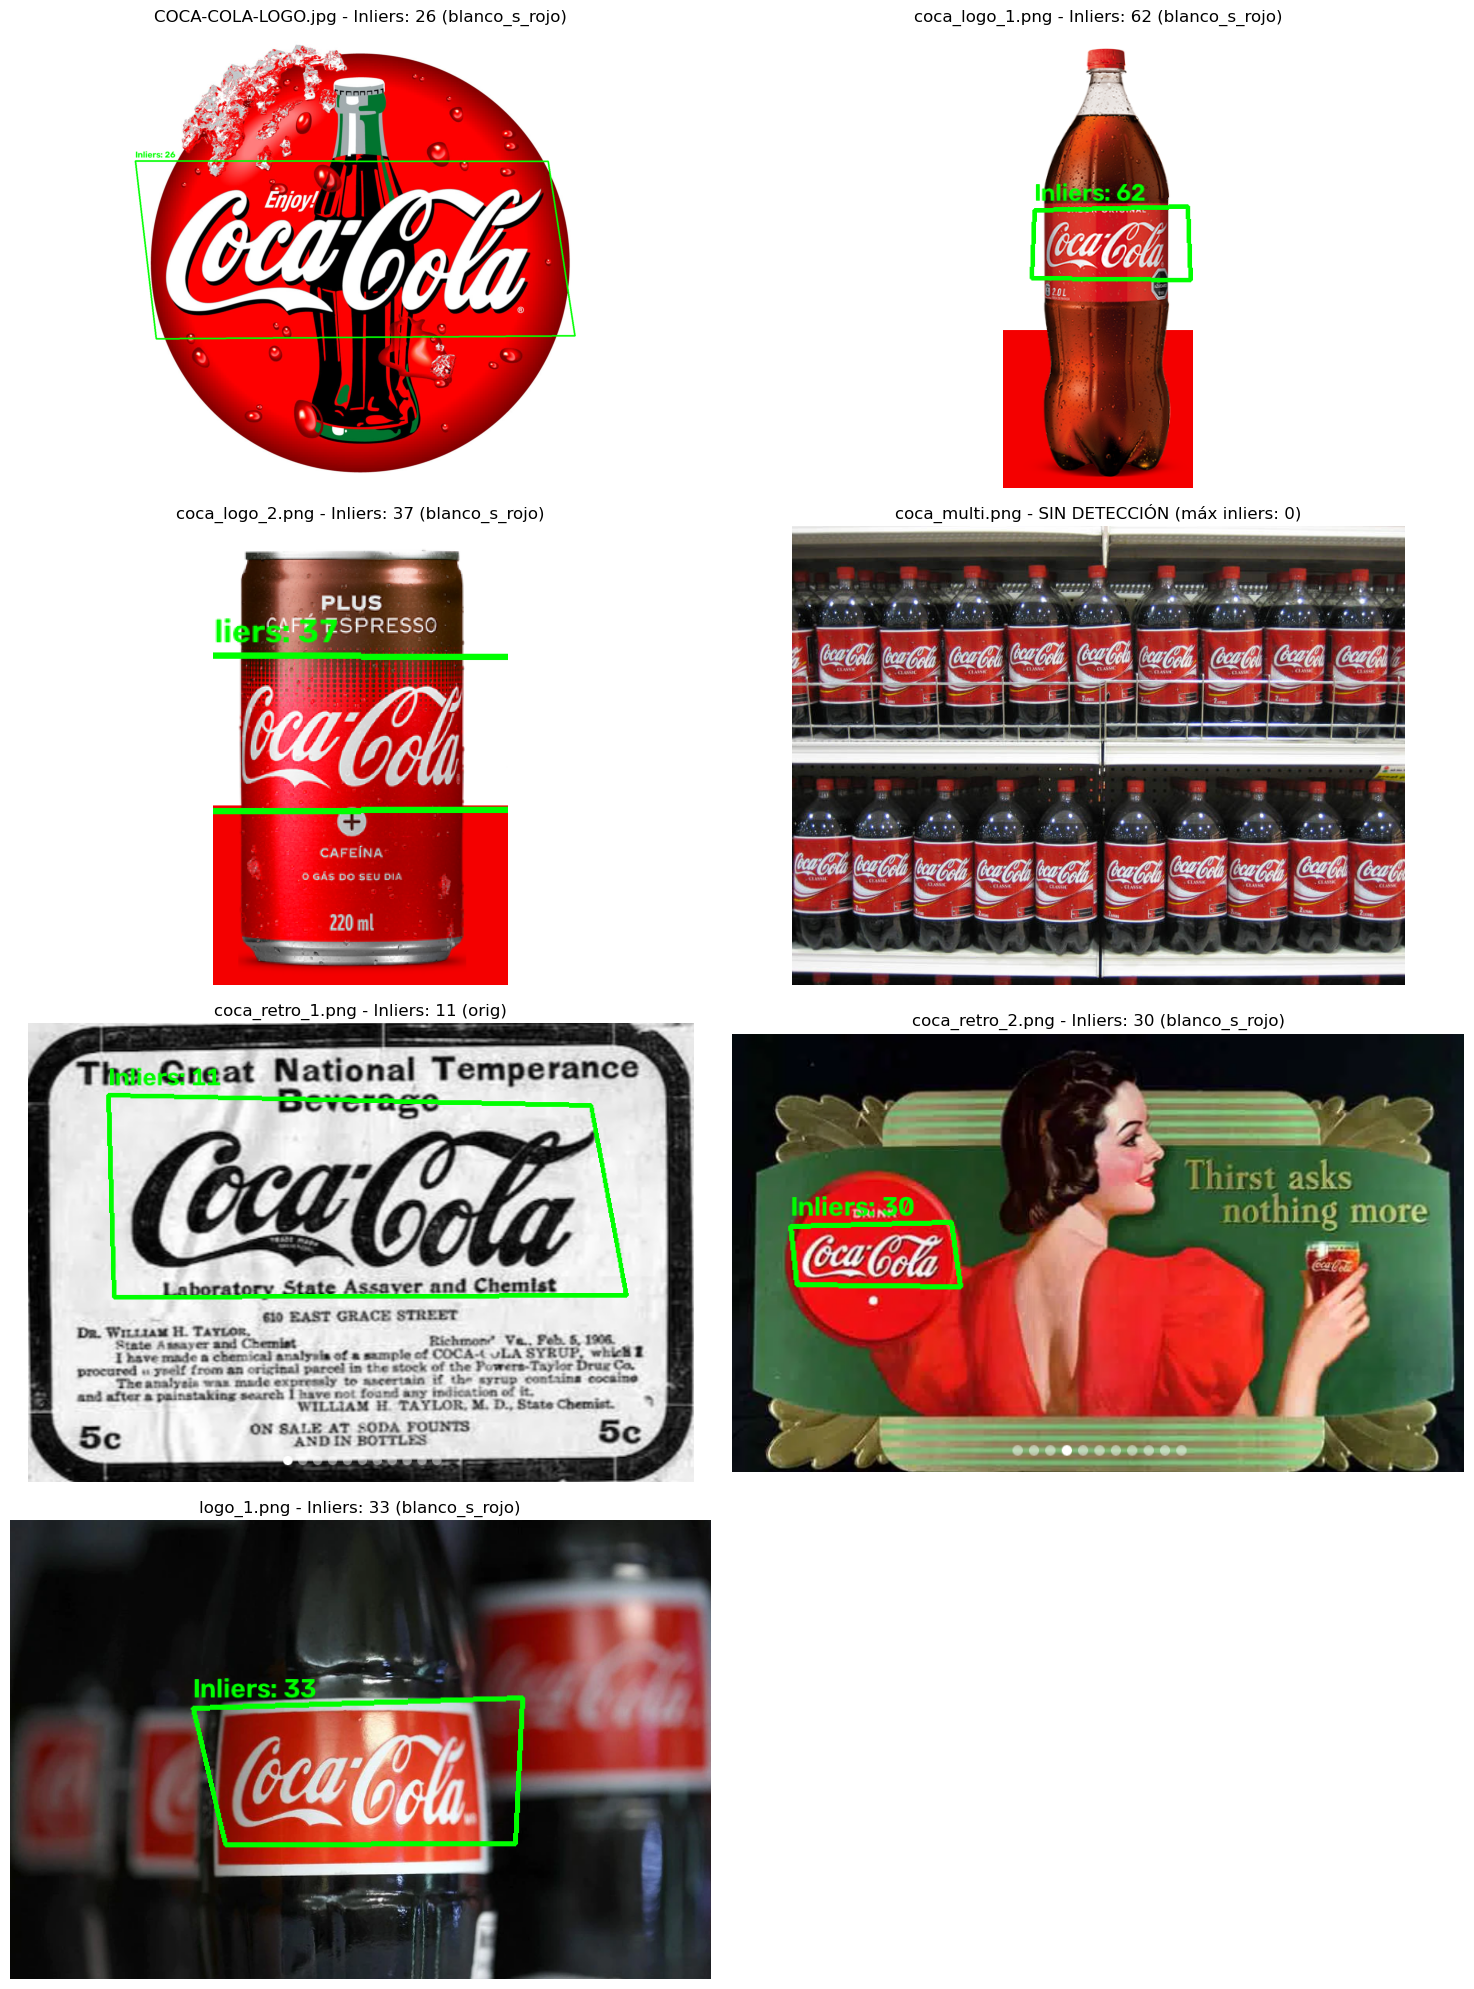

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# CONFIGURACIÓN
TEMPLATES_DIR = 'template'
IMAGES_DIR    = 'images'
MIN_INLIERS   = 8
LOWE_RATIO    = 0.80
RANSAC_THRESH = 4.0
TEMPLATE_W    = 500
EXTS = ('.png', '.jpg', '.jpeg')


def load_gray(path):
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        return None
    if img.ndim == 3 and img.shape[2] == 4:
        a = img[:, :, 3:4].astype(np.float32) / 255.0
        img = (img[:, :, :3].astype(np.float32) * a + 255.0 * (1 - a)).astype(np.uint8)
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img


def make_variants(t):
    """Genera versiones del logo con distinta polaridad/contraste."""
    scale = TEMPLATE_W / t.shape[1]
    t = cv2.resize(t, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

    thr, _ = cv2.threshold(t, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    dark_letters = np.median(t) > thr            # fondo claro -> letras oscuras
    letters = (t < thr) if dark_letters else (t >= thr)

    def build(fg, bg):
        v = np.where(letters, fg, bg).astype(np.uint8)
        return cv2.GaussianBlur(v, (3, 3), 0)    # suavizado leve, parecido a una foto

    return {
        'orig':          t,
        'negro_s_blanco': build(20, 245),
        'blanco_s_rojo':  build(245, 70),        # rojo Coca-Cola ≈ gris 70
        'blanco_s_oscuro': build(245, 25),
    }


def quad_is_valid(quad, img_shape):
    pts = quad.reshape(4, 2).astype(np.float32)
    if not cv2.isContourConvex(pts):
        return False
    area = cv2.contourArea(pts)
    if not (0.0005 * img_shape[0] * img_shape[1] < area < 1.2 * img_shape[0] * img_shape[1]):
        return False
    s = [np.linalg.norm(pts[i] - pts[(i + 1) % 4]) for i in range(4)]
    if min(s) < 1e-3:
        return False
    if max(s[0], s[2]) / min(s[0], s[2]) > 3.0 or max(s[1], s[3]) / min(s[1], s[3]) > 3.0:
        return False
    return True

def aspect_ok(quad, tpl_w, tpl_h, tol=0.4):
    pts = quad.reshape(4, 2)
    w = (np.linalg.norm(pts[1] - pts[0]) + np.linalg.norm(pts[2] - pts[3])) / 2
    h = (np.linalg.norm(pts[3] - pts[0]) + np.linalg.norm(pts[2] - pts[1])) / 2
    return h > 1 and abs((w / h) / (tpl_w / tpl_h) - 1) < tol


def detect_logo_sift(img_path, templates, sift, bf, clahe):
    img_color = cv2.imread(img_path)
    if img_color is None:
        return None, None, 0
    gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

    up = 1.0
    if max(gray.shape) < 1200:
        up = 1400.0 / max(gray.shape)
        gray = cv2.resize(gray, None, fx=up, fy=up, interpolation=cv2.INTER_CUBIC)
    gray = clahe.apply(gray)

    kp_i, des_i = sift.detectAndCompute(gray, None)
    best, top_any = None, 0

    if des_i is not None and len(kp_i) >= 4:
        for name, (t, kp_t, des_t) in templates.items():
            pairs = bf.knnMatch(des_t, des_i, k=2)
            good = [p[0] for p in pairs
                    if len(p) == 2 and p[0].distance < LOWE_RATIO * p[1].distance]
            if len(good) < 4:
                continue

            src = np.float32([kp_t[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
            dst = np.float32([kp_i[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
            H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THRESH)
            if H is None:
                continue

            inliers = int(mask.sum())
            h, w = t.shape
            corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
            quad = cv2.perspectiveTransform(corners, H)

            if not quad_is_valid(quad, gray.shape):
                continue
            top_any = max(top_any, inliers)
            if inliers >= MIN_INLIERS and (best is None or inliers > best[0]):
                best = (inliers, quad / up, name)

    out = img_color.copy()
    if best is not None:
        inliers, quad, name = best
        cv2.polylines(out, [np.int32(quad)], True, (0, 255, 0), 4)
        x, y = np.int32(quad[0, 0])
        cv2.putText(out, f"Inliers: {inliers}", (int(x), max(int(y) - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
    return out, best, top_any


sift = cv2.SIFT_create(contrastThreshold=0.01, edgeThreshold=15)
bf = cv2.BFMatcher(cv2.NORM_L2)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

templates = {}
for f in sorted(os.listdir(TEMPLATES_DIR)):
    if not f.lower().endswith(EXTS):
        continue
    t = load_gray(os.path.join(TEMPLATES_DIR, f))
    if t is None:
        continue
    for vname, v in make_variants(t).items():
        kp, des = sift.detectAndCompute(v, None)
        if des is not None and len(kp) >= 4:
            templates[f"{f}:{vname}"] = (v, kp, des)
            print(f"{f}:{vname} -> {len(kp)} puntos clave")

if not templates:
    raise SystemExit("No hay templates válidos.")

image_files = sorted(os.path.join(IMAGES_DIR, f) for f in os.listdir(IMAGES_DIR)
                     if f.lower().endswith(EXTS))
cols = 2
rows = int(np.ceil(len(image_files) / cols))
fig = plt.figure(figsize=(15, 5 * rows))

print("\nRESULTADOS\n" + "-" * 70)
for idx, img_p in enumerate(image_files):
    img_res, best, top_any = detect_logo_sift(img_p, templates, sift, bf, clahe)
    if img_res is None:
        continue
    base = os.path.basename(img_p)
    if best:
        title = f"{base} - Inliers: {best[0]} ({best[2].split(':')[1]})"
        print(f"{base:<26} DETECTADO  inliers={best[0]:<4} variante={best[2]}")
    else:
        title = f"{base} - SIN DETECCIÓN (máx inliers: {top_any})"
        print(f"{base:<26} sin detección (máx inliers válidos: {top_any})")
    ax = fig.add_subplot(rows, cols, idx + 1)
    ax.imshow(cv2.cvtColor(img_res, cv2.COLOR_BGR2RGB))
    ax.set_title(title, fontsize=12)
    ax.axis('off')

plt.tight_layout()
plt.show()

#### 2. Detectar múltiples instancias del logotipo en `coca_multi.png`.

#1  caja=(28,147,120,187)  score=0.45
#2  caja=(275,146,367,186)  score=0.47
#3  caja=(366,146,458,186)  score=0.39
#4  caja=(625,149,717,189)  score=0.36
#5  caja=(705,149,798,190)  score=0.48
#6  caja=(107,151,199,191)  score=0.47
#7  caja=(199,150,291,190)  score=0.41
#8  caja=(442,150,534,190)  score=0.43
#9  caja=(542,151,634,191)  score=0.39
#10 caja=(0,420,83,460)  score=0.41
#11 caja=(70,422,162,462)  score=0.45
#12 caja=(147,427,239,467)  score=0.47
#13 caja=(232,429,324,469)  score=0.41
#14 caja=(303,429,399,470)  score=0.44
#15 caja=(403,430,495,470)  score=0.44
#16 caja=(485,424,577,464)  score=0.45
#17 caja=(562,428,654,468)  score=0.46
#18 caja=(654,424,746,464)  score=0.38
#19 caja=(733,428,798,469)  score=0.54

Instancias detectadas: 19


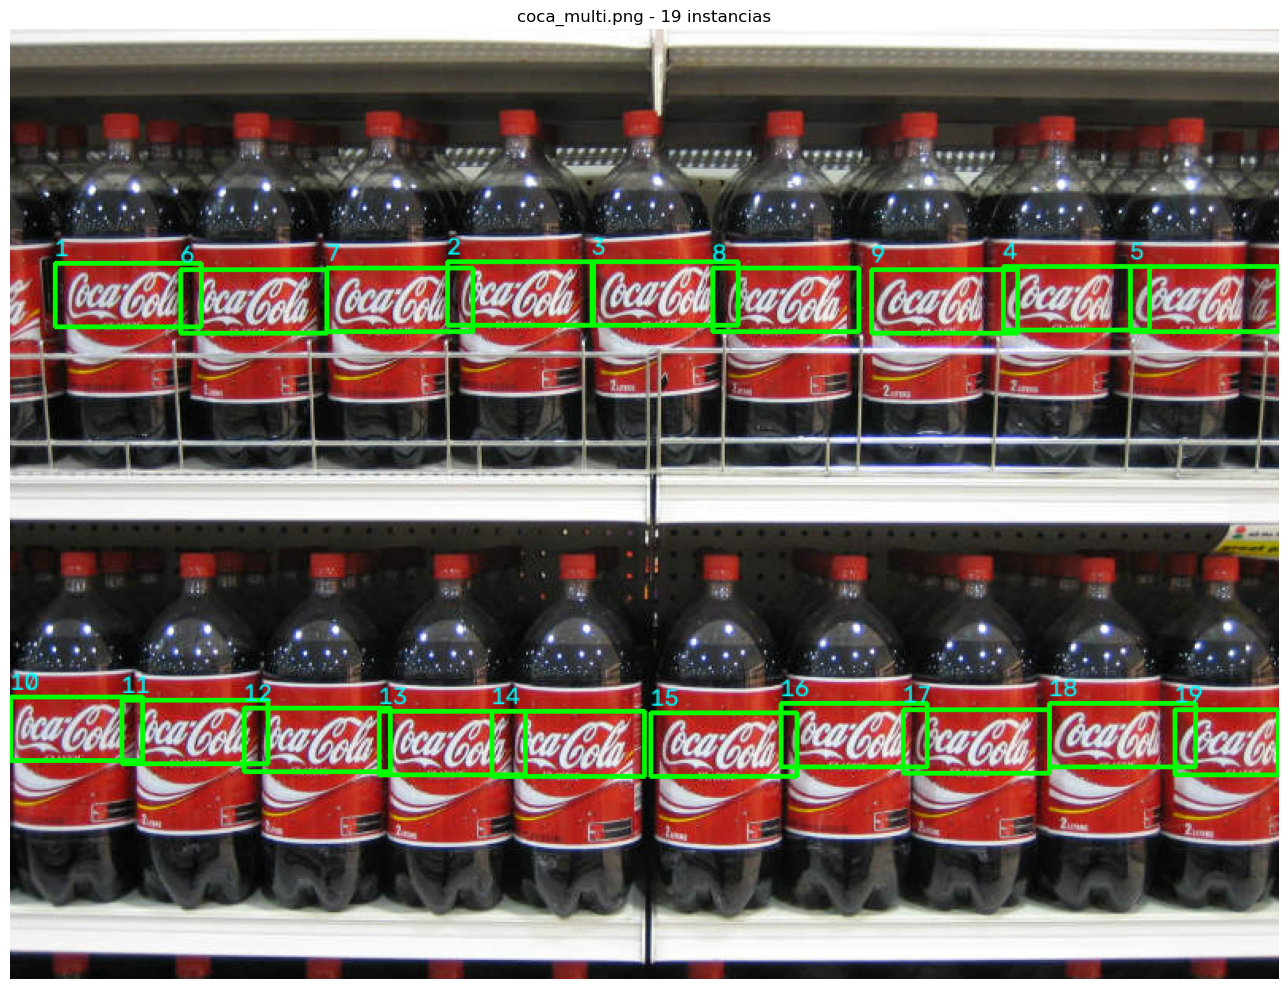

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# CONFIGURACIÓN
IMG_PATH      = 'images/coca_multi.png'
TEMPLATE_PATH = 'template/pattern.png'
USE_VARIANT   = True
WIDTHS        = range(80, 121, 4)
THRESH        = 0.27
MIN_RED       = 0.30
PAD           = 50

def load_gray(path):
    im = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if im is None:
        raise SystemExit(f"No se pudo leer {path}")
    if im.ndim == 3 and im.shape[2] == 4:
        a = im[:, :, 3:4].astype(np.float32) / 255.0
        im = (im[:, :, :3].astype(np.float32) * a + 255.0 * (1 - a)).astype(np.uint8)
    return cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) if im.ndim == 3 else im


def white_on_red(t, width=300):
    t = cv2.resize(t, None, fx=width / t.shape[1], fy=width / t.shape[1], interpolation=cv2.INTER_AREA)
    thr, _ = cv2.threshold(t, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    letters = (t < thr) if np.median(t) > thr else (t >= thr)
    return cv2.GaussianBlur(np.where(letters, 245, 70).astype(np.uint8), (3, 3), 0)


def detect_multi(img_path, template_gray):
    img = cv2.imread(img_path)
    imgp = cv2.copyMakeBorder(img, PAD, PAD, PAD, PAD, cv2.BORDER_REPLICATE)

    clahe = cv2.createCLAHE(2.0, (8, 8))
    g = clahe.apply(cv2.cvtColor(imgp, cv2.COLOR_BGR2GRAY))
    t = clahe.apply(template_gray)

    hsv = cv2.cvtColor(imgp, cv2.COLOR_BGR2HSV)
    red = (((hsv[..., 0] < 10) | (hsv[..., 0] > 170)) &
           (hsv[..., 1] > 110) & (hsv[..., 2] > 70)).astype(np.uint8)
    integral = cv2.integral(red)

    def red_frac(x1, y1, x2, y2):
        x1, y1 = max(x1, 0), max(y1, 0)
        x2, y2 = min(x2, red.shape[1]), min(y2, red.shape[0])
        s = integral[y2, x2] - integral[y1, x2] - integral[y2, x1] + integral[y1, x1]
        return s / max((x2 - x1) * (y2 - y1), 1)

    cands = []
    for w in WIDTHS:
        h = int(t.shape[0] * w / t.shape[1])
        tt = cv2.resize(t, (w, h), interpolation=cv2.INTER_AREA)
        res = cv2.matchTemplate(g, tt, cv2.TM_CCOEFF_NORMED)
        for y, x in zip(*np.where(res >= THRESH)):
            if red_frac(x - 8, y - 8, x + w + 8, y + h + 8) >= MIN_RED:   # 2) filtro de color
                cands.append((x, y, w, h, float(res[y, x])))

    cands.sort(key=lambda c: -c[4])
    keep = []
    for x, y, w, h, s in cands:
        cx, cy = x + w / 2, y + h / 2
        if any(abs(cx - (k[0] + k[2] / 2)) < 0.6 * w and abs(cy - (k[1] + k[3] / 2)) < 2.0 * h for k in keep):
            continue
        keep.append((x, y, w, h, s))

    H, W = img.shape[:2]
    dets = []
    for x, y, w, h, s in keep:
        x1, y1 = max(x - PAD, 0), max(y - PAD, 0)
        x2, y2 = min(x - PAD + w, W - 1), min(y - PAD + h, H - 1)
        dets.append((x1, y1, x2, y2, s))
    return img, dets


tpl = load_gray(TEMPLATE_PATH)
if USE_VARIANT:
    tpl = white_on_red(tpl)

img, dets = detect_multi(IMG_PATH, tpl)
out = img.copy()
for i, (x1, y1, x2, y2, s) in enumerate(sorted(dets, key=lambda d: (d[1] // 150, d[0])), 1):
    cv2.rectangle(out, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(out, str(i), (x1, max(y1 - 4, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 1)
    print(f"#{i:<2} caja=({x1},{y1},{x2},{y2})  score={s:.2f}")
print(f"\nInstancias detectadas: {len(dets)}")

plt.figure(figsize=(14, 10))
plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
plt.title(f"coca_multi.png - {len(dets)} instancias")
plt.axis('off')
plt.tight_layout()
plt.show()

#### 3. Generalizar el algoritmo para todas las imágenes del dataset visualizando Bounding Boxes y nivel de confianza.

Imágenes procesadas: 7

Imagen                         N.º   Puntuaciones
-------------------------------------------------------------------------------------
COCA-COLA-LOGO.jpg               1   0.82
coca_logo_1.png                  1   0.98
coca_logo_2.png                  1   0.92
coca_multi.png                2849   0.63, 0.62, 0.62, 0.62, 0.62, 0.62, 0.62, 0.62, 0.62, 0.61, 0.61, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60, 0.60,

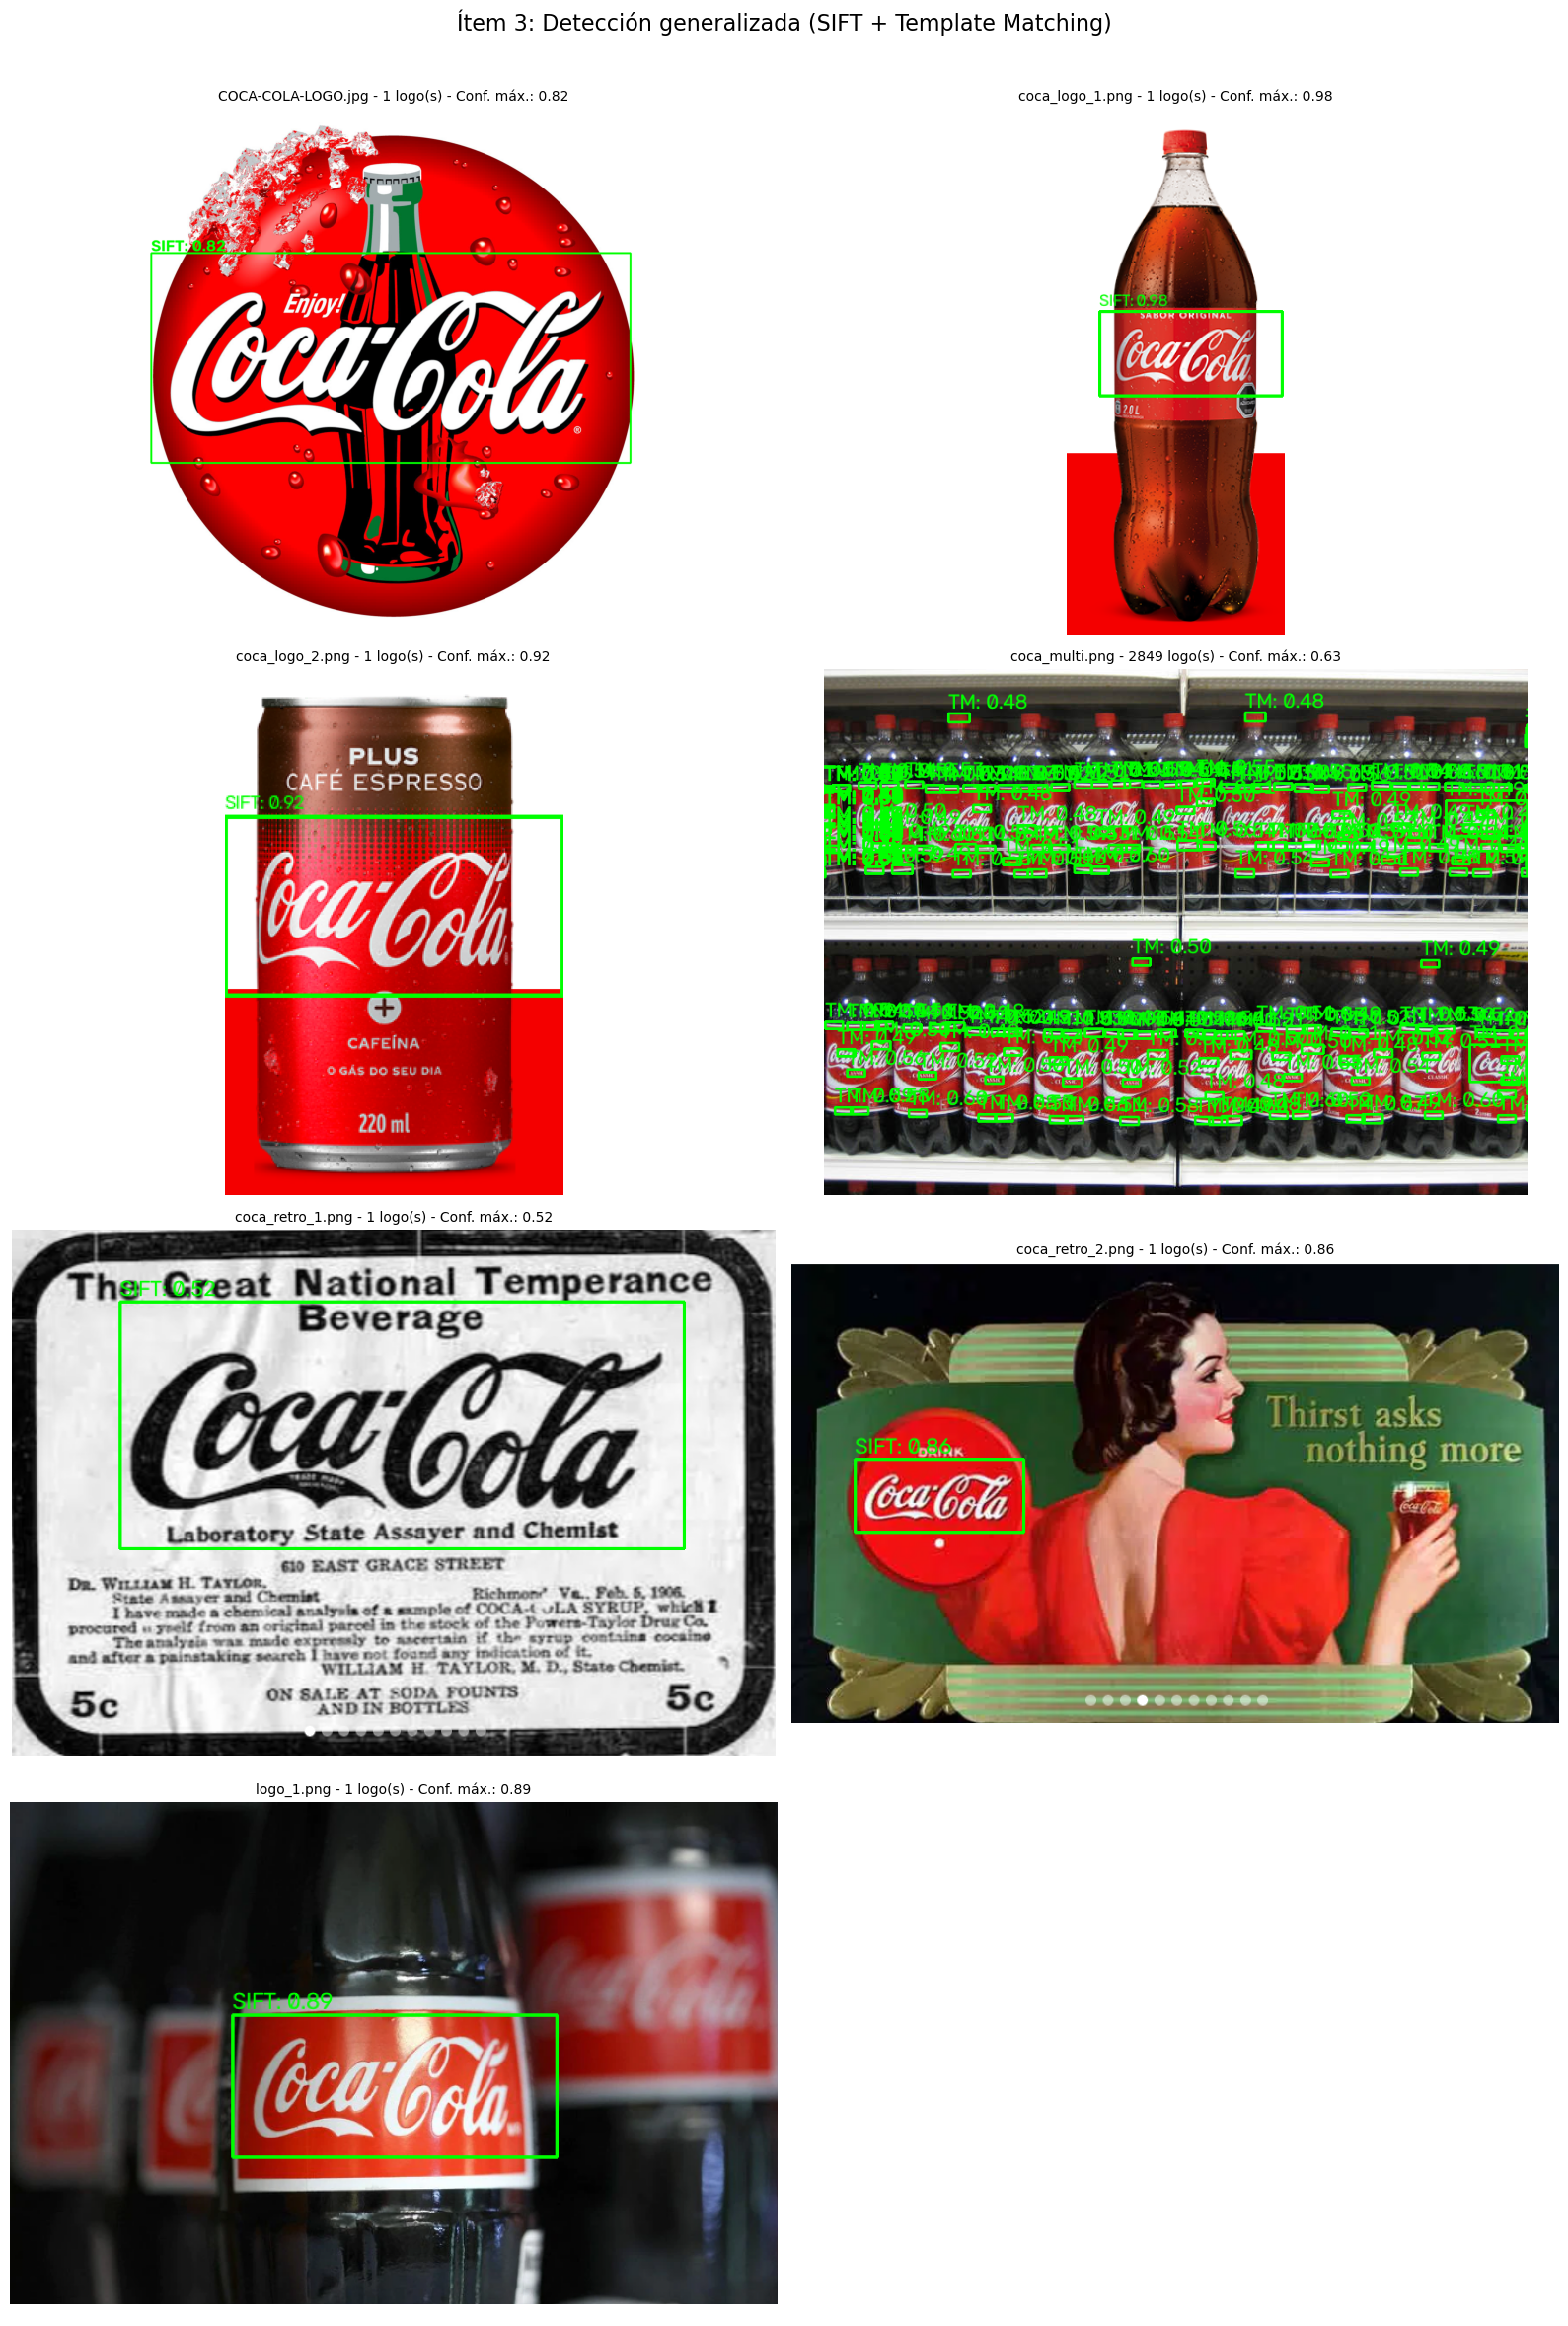

In [63]:
# CONFIGURACIÓN

TEMPLATE_PATH = "template/pattern.png"
IMAGES_DIR = "images"
EXTS = (".png", ".jpg", ".jpeg")

# SIFT + RANSAC
MIN_INLIERS = 8
LOWE_RATIO = 0.80
RANSAC_THRESH = 4.0
TEMPLATE_W = 500

# Template Matching
REL_WIDTHS = (0.025, 0.22)
MIN_LOGO_W = 20
PAD = 50

# Umbrales de coincidencia
TM_SCAN_THRESH = 0.36
TM_ACCEPT = 0.44
TM_MIN_ACCEPT = 0.39
TM_MAX_ACCEPT = 0.48
TM_RELATIVE = 0.82

# Instancias adicionales cuando SIFT ya encontró un logotipo
TM_SECOND_MIN = 0.40
TM_SECOND_MAX = 0.47
SIFT_SCALE = (0.65, 1.40)

# Filtro de contexto rojo
MIN_RED = 0.25

# Refinamiento SIFT
REFINE_MIN = 0.30

# Eliminación de duplicados
IOU_THRESH = 0.18
CENTER_FACTOR_X = 0.35
CENTER_FACTOR_Y = 0.65
MAX_SIZE_RATIO = 2.2

OUTPUT_PATH = "out_unified.png"


def load_gray(path):
    im = cv2.imread(path, cv2.IMREAD_UNCHANGED)

    if im is None:
        return None

    if im.ndim == 3 and im.shape[2] == 4:
        alpha = im[:, :, 3:4].astype(np.float32) / 255.0

        im = (
            im[:, :, :3].astype(np.float32) * alpha
            + 255.0 * (1.0 - alpha)
        ).astype(np.uint8)

    if im.ndim == 3:
        return cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

    return im


def make_variants(template):
    scale = TEMPLATE_W / template.shape[1]

    template = cv2.resize(
        template,
        None,
        fx=scale,
        fy=scale,
        interpolation=cv2.INTER_AREA
    )

    threshold, _ = cv2.threshold(
        template,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    if np.median(template) > threshold:
        letters = template < threshold
    else:
        letters = template >= threshold

    def build(foreground, background):
        result = np.where(
            letters,
            foreground,
            background
        ).astype(np.uint8)

        return cv2.GaussianBlur(result, (3, 3), 0)

    return {
        "orig": template,
        "negro_s_blanco": build(20, 245),
        "blanco_s_rojo": build(245, 70),
        "blanco_s_oscuro": build(245, 25)
    }


def build_variants_kp(variants, sift):
    result = {}

    for name, template in variants.items():
        kp, des = sift.detectAndCompute(template, None)

        if des is not None and len(kp) >= 4:
            result[name] = (template, kp, des)

    return result


# VALIDACIÓN GEOMÉTRICA PARA SIFT

def quad_is_valid(quad, shape):
    pts = quad.reshape(4, 2).astype(np.float32)

    if not cv2.isContourConvex(pts):
        return False

    area = cv2.contourArea(pts)
    image_area = shape[0] * shape[1]

    if not (0.0005 * image_area < area < 1.2 * image_area):
        return False

    sides = [
        np.linalg.norm(pts[i] - pts[(i + 1) % 4])
        for i in range(4)
    ]

    if min(sides) < 1e-3:
        return False

    if max(sides[0], sides[2]) / min(sides[0], sides[2]) >= 3.0:
        return False

    if max(sides[1], sides[3]) / min(sides[1], sides[3]) >= 3.0:
        return False

    return True


# ETAPA 1: SIFT + RANSAC

def stage_sift(img, variants_kp, sift, bf):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    scale = (
        1400.0 / max(gray.shape)
        if max(gray.shape) < 1200
        else 1.0
    )

    if scale != 1.0:
        gray = cv2.resize(
            gray,
            None,
            fx=scale,
            fy=scale,
            interpolation=cv2.INTER_CUBIC
        )

    gray = cv2.createCLAHE(2.0, (8, 8)).apply(gray)

    kp_img, des_img = sift.detectAndCompute(gray, None)

    if des_img is None or len(kp_img) < 4:
        return None

    best = None

    for name, (template, kp_template, des_template) in variants_kp.items():

        matches = bf.knnMatch(des_template, des_img, k=2)

        good = [
            pair[0]
            for pair in matches
            if len(pair) == 2
            and pair[0].distance < LOWE_RATIO * pair[1].distance
        ]

        if len(good) < 4:
            continue

        src = np.float32([
            kp_template[m.queryIdx].pt for m in good
        ]).reshape(-1, 1, 2)

        dst = np.float32([
            kp_img[m.trainIdx].pt for m in good
        ]).reshape(-1, 1, 2)

        H, mask = cv2.findHomography(
            src,
            dst,
            cv2.RANSAC,
            RANSAC_THRESH
        )

        if H is None or mask is None:
            continue

        inliers = int(mask.sum())

        h, w = template.shape

        corners = np.float32([
            [0, 0], [w, 0], [w, h], [0, h]
        ]).reshape(-1, 1, 2)

        quad = cv2.perspectiveTransform(corners, H)

        if (
            inliers >= MIN_INLIERS
            and quad_is_valid(quad, gray.shape)
            and (best is None or inliers > best[0])
        ):
            best = (
                inliers,
                (quad / scale).reshape(4, 2),
                name
            )

    if best is None:
        return None

    inliers, quad, name = best

    x1, y1 = quad.min(axis=0)
    x2, y2 = quad.max(axis=0)

    H_img, W_img = img.shape[:2]

    box = (
        max(int(x1), 0),
        max(int(y1), 0),
        min(int(x2), W_img - 1),
        min(int(y2), H_img - 1)
    )

    if box[2] <= box[0] or box[3] <= box[1]:
        return None

    confidence = 1.0 - np.exp(-inliers / 15.0)

    return {
        "box": box,
        "conf": float(confidence),
        "src": "SIFT",
        "variant": name
    }


# REFINAMIENTO DE LA BOUNDING BOX

def refine_box(img, box, template_gray):
    H_img, W_img = img.shape[:2]

    x1, y1, x2, y2 = box
    w0 = x2 - x1

    margin = int(0.5 * w0)

    wx1 = max(x1 - margin, 0)
    wy1 = max(y1 - margin, 0)
    wx2 = min(x2 + margin, W_img)
    wy2 = min(y2 + margin, H_img)

    roi_color = img[wy1:wy2, wx1:wx2]

    if roi_color.size == 0:
        return box

    roi = cv2.createCLAHE(2.0, (8, 8)).apply(
        cv2.cvtColor(roi_color, cv2.COLOR_BGR2GRAY)
    )

    template = cv2.createCLAHE(2.0, (8, 8)).apply(template_gray)

    best = None

    for width in np.linspace(0.6 * w0, 1.4 * w0, 17):
        width = int(width)

        height = int(
            template.shape[0] * width / template.shape[1]
        )

        if (
            width < 16 or height < 8
            or width >= roi.shape[1]
            or height >= roi.shape[0]
        ):
            continue

        resized = cv2.resize(
            template,
            (width, height),
            interpolation=cv2.INTER_AREA
        )

        result = cv2.matchTemplate(
            roi, resized, cv2.TM_CCOEFF_NORMED
        )

        _, score, _, location = cv2.minMaxLoc(result)

        if best is None or score > best[0]:
            best = (
                score,
                wx1 + location[0],
                wy1 + location[1],
                width,
                height
            )

    if best is None or best[0] < REFINE_MIN:
        return box

    _, x, y, width, height = best

    return (
        max(x, 0),
        max(y, 0),
        min(x + width, W_img - 1),
        min(y + height, H_img - 1)
    )


def sift_with_refine(img, variants_kp, sift, bf):
    result = stage_sift(img, variants_kp, sift, bf)

    if result is not None:
        template = variants_kp[result["variant"]][0]

        result["box"] = refine_box(
            img,
            result["box"],
            template
        )

    return result


# FILTRO DE CONTEXTO ROJO

def make_red_mask(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    red = (
        (
            (hsv[:, :, 0] < 10)
            | (hsv[:, :, 0] > 170)
        )
        & (hsv[:, :, 1] > 110)
        & (hsv[:, :, 2] > 70)
    )

    return red.astype(np.float32)


# ETAPA 2: TEMPLATE MATCHING MULTI-ESCALA

def stage_tm(img, template, widths, red_mask, threshold=TM_SCAN_THRESH):
    """
    Encuentra candidatos a distintas escalas.

    Se amplía el rango de tamaños para admitir logotipos pequeños
    y se usa un vecindario proporcional al tamaño de la plantilla
    para reducir máximos repetidos.
    """

    img_padded = cv2.copyMakeBorder(
        img,
        PAD, PAD, PAD, PAD,
        cv2.BORDER_REPLICATE
    )

    red_padded = cv2.copyMakeBorder(
        red_mask,
        PAD, PAD, PAD, PAD,
        cv2.BORDER_REPLICATE
    )

    clahe = cv2.createCLAHE(2.0, (8, 8))

    gray = clahe.apply(
        cv2.cvtColor(img_padded, cv2.COLOR_BGR2GRAY)
    )

    tpl = clahe.apply(template)

    candidates = []

    for width in widths:
        width = int(round(width))

        height = int(tpl.shape[0] * width / tpl.shape[1])

        if (
            width < MIN_LOGO_W
            or height < 8
            or width >= gray.shape[1]
            or height >= gray.shape[0]
        ):
            continue

        resized_tpl = cv2.resize(
            tpl,
            (width, height),
            interpolation=cv2.INTER_AREA
        )

        result = cv2.matchTemplate(
            gray,
            resized_tpl,
            cv2.TM_CCOEFF_NORMED
        )

        kernel_w = max(7, int(width * 0.40)) | 1
        kernel_h = max(5, int(height * 0.60)) | 1

        dilated = cv2.dilate(
            result,
            np.ones((kernel_h, kernel_w), dtype=np.uint8)
        )

        peaks = (
            (result >= dilated - 1e-6)
            & (result >= threshold)
        )

        ys, xs = np.where(peaks)

        if len(xs) == 0:
            continue

        red_fraction = cv2.boxFilter(
            red_padded,
            ddepth=-1,
            ksize=(width + 12, height + 12),
            normalize=True,
            borderType=cv2.BORDER_CONSTANT
        )

        valid = (
            red_fraction[
                ys + height // 2,
                xs + width // 2
            ] >= MIN_RED
        )

        for x, y in zip(xs[valid], ys[valid]):
            candidates.append({
                "box": (
                    max(int(x) - PAD, 0),
                    max(int(y) - PAD, 0),
                    min(int(x) - PAD + width, img.shape[1] - 1),
                    min(int(y) - PAD + height, img.shape[0] - 1)
                ),
                "conf": float(result[y, x]),
                "src": "TM"
            })

    return candidates


# ELIMINACIÓN DE DUPLICADOS

def box_iou(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    intersection = (
        max(0, ix2 - ix1) * max(0, iy2 - iy1)
    )

    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)

    union = area_a + area_b - intersection

    return intersection / (union + 1e-9)


def is_duplicate(a, b):
    box_a = a["box"]
    box_b = b["box"]

    if box_iou(box_a, box_b) >= IOU_THRESH:
        return True

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    wa, ha = ax2 - ax1, ay2 - ay1
    wb, hb = bx2 - bx1, by2 - by1

    if min(wa, ha, wb, hb) <= 0:
        return False

    size_ratio = max(wa, wb) / max(1, min(wa, wb))

    if size_ratio > MAX_SIZE_RATIO:
        return False

    cxa, cya = (ax1 + ax2) / 2, (ay1 + ay2) / 2
    cxb, cyb = (bx1 + bx2) / 2, (by1 + by2) / 2

    dx = abs(cxa - cxb)
    dy = abs(cya - cyb)

    return (
        dx < CENTER_FACTOR_X * max(wa, wb)
        and dy < CENTER_FACTOR_Y * max(ha, hb)
    )


def nms(detections):
    """
    Conserva detecciones fuertes y elimina cajas repetidas.
    Las detecciones SIFT tienen prioridad sobre las de TM.
    """

    detections = sorted(
        detections,
        key=lambda d: (
            d["src"] == "SIFT",
            d["conf"]
        ),
        reverse=True
    )

    accepted = []

    for detection in detections:
        if any(
            is_duplicate(detection, kept)
            for kept in accepted
        ):
            continue

        accepted.append(detection)

    return accepted


# DETECTOR COMBINADO

def detect_logos(img, sift_result, template_tm):
    red_mask = make_red_mask(img)

    detections = []

    if sift_result is not None:
        detections.append(sift_result)

        x1, _, x2, _ = sift_result["box"]
        sift_width = max(x2 - x1, MIN_LOGO_W)

        widths = np.linspace(
            SIFT_SCALE[0] * sift_width,
            SIFT_SCALE[1] * sift_width,
            15
        )

        candidates = stage_tm(
            img,
            template_tm,
            widths,
            red_mask
        )

        if candidates:
            best_score = max(d["conf"] for d in candidates)

            adaptive_threshold = max(
                TM_SECOND_MIN,
                min(TM_SECOND_MAX, best_score * TM_RELATIVE)
            )

            candidates = [
                d for d in candidates
                if d["conf"] >= adaptive_threshold
            ]

        detections.extend(candidates)

    else:
        image_width = img.shape[1]

        min_width = max(
            MIN_LOGO_W,
            REL_WIDTHS[0] * image_width
        )

        max_width = REL_WIDTHS[1] * image_width

        widths = np.geomspace(
            min_width,
            max_width,
            55
        )

        candidates = stage_tm(
            img,
            template_tm,
            widths,
            red_mask
        )

        if candidates:
            best_score = max(d["conf"] for d in candidates)

            if best_score < TM_ACCEPT:
                candidates = []
            else:
                adaptive_threshold = max(
                    TM_MIN_ACCEPT,
                    min(TM_MAX_ACCEPT, best_score * TM_RELATIVE)
                )

                candidates = [
                    d for d in candidates
                    if d["conf"] >= adaptive_threshold
                ]

        detections.extend(candidates)

    return nms(detections)


# TODAS LAS IMÁGENES DEL DATASET


if __name__ == "__main__":

    if not os.path.isfile(TEMPLATE_PATH):
        raise SystemExit(
            f"No existe la plantilla: {TEMPLATE_PATH}"
        )

    if not os.path.isdir(IMAGES_DIR):
        raise SystemExit(
            f"No existe la carpeta de imágenes: {IMAGES_DIR}"
        )

    template_original = load_gray(TEMPLATE_PATH)

    if template_original is None:
        raise SystemExit(
            f"No se pudo leer la plantilla: {TEMPLATE_PATH}"
        )

    sift = cv2.SIFT_create(
        contrastThreshold=0.01,
        edgeThreshold=15
    )

    bf = cv2.BFMatcher(cv2.NORM_L2)

    variants = make_variants(template_original)

    variants_kp = build_variants_kp(variants, sift)

    if not variants_kp:
        raise SystemExit(
            "No se pudieron obtener descriptores SIFT de la plantilla."
        )

    template_tm = variants["blanco_s_rojo"]

    files = sorted(
        os.path.join(IMAGES_DIR, filename)
        for filename in os.listdir(IMAGES_DIR)
        if filename.lower().endswith(EXTS)
    )

    images = {
        path: cv2.imread(path)
        for path in files
    }

    valid_files = [
        path for path in files
        if images[path] is not None
    ]

    if not valid_files:
        raise SystemExit(
            f"No se encontraron imágenes legibles en {IMAGES_DIR}"
        )

    print(f"Imágenes procesadas: {len(valid_files)}")
    print()

    # Primera pasada: intentar localizar una instancia con SIFT.
    sift_results = {
        path: sift_with_refine(
            images[path],
            variants_kp,
            sift,
            bf
        )
        for path in valid_files
    }

    # Segunda pasada: generalizar a múltiples instancias por imagen.
    columns = 2
    rows = int(np.ceil(len(valid_files) / columns))

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(16, 6 * rows),
        squeeze=False
    )

    total = 0

    print(f"{'Imagen':<28}{'N.º':>6}   Puntuaciones")
    print("-" * 85)

    for index, path in enumerate(valid_files):
        img = images[path]

        detections = detect_logos(
            img,
            sift_results[path],
            template_tm
        )

        output = img.copy()

        max_dimension = max(output.shape[:2])

        line_width = max(
            2,
            int(round(max_dimension / 450))
        )

        font_scale = max(
            0.45,
            max_dimension / 1000
        )

        for detection in detections:
            x1, y1, x2, y2 = detection["box"]

            cv2.rectangle(
                output,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                line_width
            )

            method = detection["src"]
            label = f"{method}: {detection['conf']:.2f}"

            text_y = max(
                y1 - 5,
                int(18 * font_scale)
            )

            cv2.putText(
                output,
                label,
                (x1, text_y),
                cv2.FONT_HERSHEY_SIMPLEX,
                font_scale,
                (0, 255, 0),
                max(1, line_width - 1),
                cv2.LINE_AA
            )

        total += len(detections)

        filename = os.path.basename(path)

        scores = ", ".join(
            f"{d['conf']:.2f}"
            for d in sorted(
                detections,
                key=lambda d: d["conf"],
                reverse=True
            )
        )

        print(
            f"{filename:<28}{len(detections):>6}   "
            f"{scores if scores else 'Sin detecciones'}"
        )

        ax = axes[index // columns][index % columns]

        ax.imshow(
            cv2.cvtColor(output, cv2.COLOR_BGR2RGB)
        )

        if detections:
            title = (
                f"{filename} - {len(detections)} logo(s) "
                f"- Conf. máx.: "
                f"{max(d['conf'] for d in detections):.2f}"
            )
        else:
            title = f"{filename} - SIN DETECCIÓN"

        ax.set_title(title, fontsize=10)
        ax.axis("off")

    for index in range(len(valid_files), rows * columns):
        axes[index // columns][index % columns].axis("off")

    plt.suptitle(
        "Ítem 3: Detección generalizada "
        "(SIFT + Template Matching)",
        fontsize=16
    )

    plt.tight_layout(rect=[0, 0, 1, 0.97])

    plt.savefig(
        OUTPUT_PATH,
        dpi=120,
        bbox_inches="tight"
    )

    print("-" * 85)
    print(f"Total de logos detectados: {total}")
    print(f"Resultado guardado en: {OUTPUT_PATH}")

    plt.show()
